In [1]:
from google.colab import files
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import csv
data = pd.read_csv('/content/Day-06_mobile_sales_data.csv', quoting=csv.QUOTE_NONE)

In [4]:
data.head()

,Product,Brand,Product Code,Product Specification,Price,Inward Date,Dispatch Date,Quantity Sold,Customer Name,Customer Location,Region,Core Specification,Processor Specification,RAM,ROM,SSD
0,Mobile Phone,Motorola,88EB4558,Site candidate activity company there bit insi...,78570,2023-08-02,2023-08-03,6,William Hess,South Kelsey,Central,NaN,Snapdragon 7 Gen,12GB,128GB,NaN
1,Laptop,Oppo,416DFEEB,Beat put care fight affect address his.,44613,2023-10-03,2023-10-06,1,Larry Smith,North Lisa,South,Ryzen 5,Ryzen 5,8GB,512GB,256GB
2,Mobile Phone,Samsung,9F975B08,Energy special low seven place audience.,159826,2025-03-19,2025-03-20,5,Leah Copeland,South Todd,Central,NaN,MediaTek Dimensity,8GB,256GB,NaN
3,Laptop,Sony,73D2A7CC,Friend record hard contain minute we role sea ...,20911,2024-02-06,2024-03-27,1,Dan Kirby,New Jordanmouth,South,i7,i7,12GB,64GB,2TB
4,Laptop,Microsoft,CCE0B80D,Program recently feeling save tree hotel people.,69832,2023-08-10,2023-09-10,4,Dean Martin,Keithton,East,i7,i7,8GB,128GB,2TB


In [5]:
data.tail()

,Product,Brand,Product Code,Product Specification,Price,Inward Date,Dispatch Date,Quantity Sold,Customer Name,Customer Location,Region,Core Specification,Processor Specification,RAM,ROM,SSD
49995,Laptop,Motorola,8C187637,Pick build kind teach mean each camera.,170385,2024-03-02,2024-04-11,6,Sara Gomez,Sylviatown,North,i3,i3,16GB,512GB,2TB
49996,Laptop,HP,0DA9E4D3,Outside policy treat he opportunity pattern.,193133,2025-01-19,2025-01-20,4,Raymond Clark,Chrismouth,West,i7,i7,8GB,1TB,512GB
49997,Laptop,Toshiba,CAD89A93,Test floor tax together out adult discover own...,66502,2024-01-16,2024-03-05,6,Joseph Martin,Huntfurt,North,i5,i5,4GB,64GB,2TB
49998,Mobile Phone,Lenovo,78566C17,Away also magazine receive such lay.,158883,2023-05-15,2023-05-25,2,Gabrielle Barnett,Heidiberg,North,NaN,Snapdragon 7s,12GB,1TB,NaN
49999,Laptop,Asus,9C3FC57C,Role ahead common listen idea few blood half.,86483,2023-08-29,2023-10-26,7,Robert Sampson,West Elizabethchester,East,i7,i7,12GB,128GB,256GB


In [6]:
data.shape

(50000, 16)

In [22]:
brand_analysis = data.groupby('Brand').agg(
    Total_Quantity_Sold=('Quantity Sold', 'sum'),
    Average_Price=('Price', 'mean'),
    Total_Revenue=('Price', lambda x: (x * data.loc[x.index, 'Quantity Sold']).sum())
).reset_index()

print("--- Brand-wise Analysis ---")
print(brand_analysis.sort_values(by='Total_Revenue', ascending=False).head(10))

region_analysis = data.groupby('Region')['Quantity Sold'].sum().reset_index()
print("\n--- Region-wise Quantity Sold ---")
print(region_analysis.sort_values(by='Quantity Sold', ascending=False))

product_analysis = data.groupby('Product')['Quantity Sold'].sum().reset_index()
print("\n--- Product Sales ---")
print(product_analysis)

--- Brand-wise Analysis ---
        Brand  Total_Quantity_Sold  Average_Price  Total_Revenue
4      Google                14412  104308.973441     1514617084
10      Nokia                14239  104432.583431     1473167125
1       Apple                14197  103728.825663     1470242666
17    Toshiba                13996  104224.778474     1454585835
16       Sony                14043  102537.992148     1442582351
15    Samsung                14033  103383.020328     1436721278
14      Redmi                13948  102836.591143     1432172989
8   Microsoft                13586  103841.411070     1430065277
9    Motorola                13888  102728.754732     1420578610
0        Acer                13854  102558.290565     1419570397

--- Region-wise Quantity Sold ---
    Region  Quantity Sold
4     West          56602
3    South          55214
2    North          55035
1     East          54745
0  Central          54093

--- Product Sales ---
        Product  Quantity Sold
0        Lap

In [8]:
data.describe()

,Price,Quantity Sold
count,50000.000000,50000.00000
mean,102641.407080,5.51378
std,56363.550361,2.88101
min,5008.000000,1.00000
25%,53487.000000,3.00000
50%,103072.000000,6.00000
75%,151396.250000,8.00000
max,199999.000000,10.00000


In [9]:
data.min(numeric_only=True)

,0
Price,5008
Quantity Sold,1


In [10]:
data.max(numeric_only=True)

,0
Price,199999
Quantity Sold,10


In [11]:
data['Quantity Sold'].unique()

array([ 6,  1,  5,  4,  3, 10,  9,  8,  7,  2])

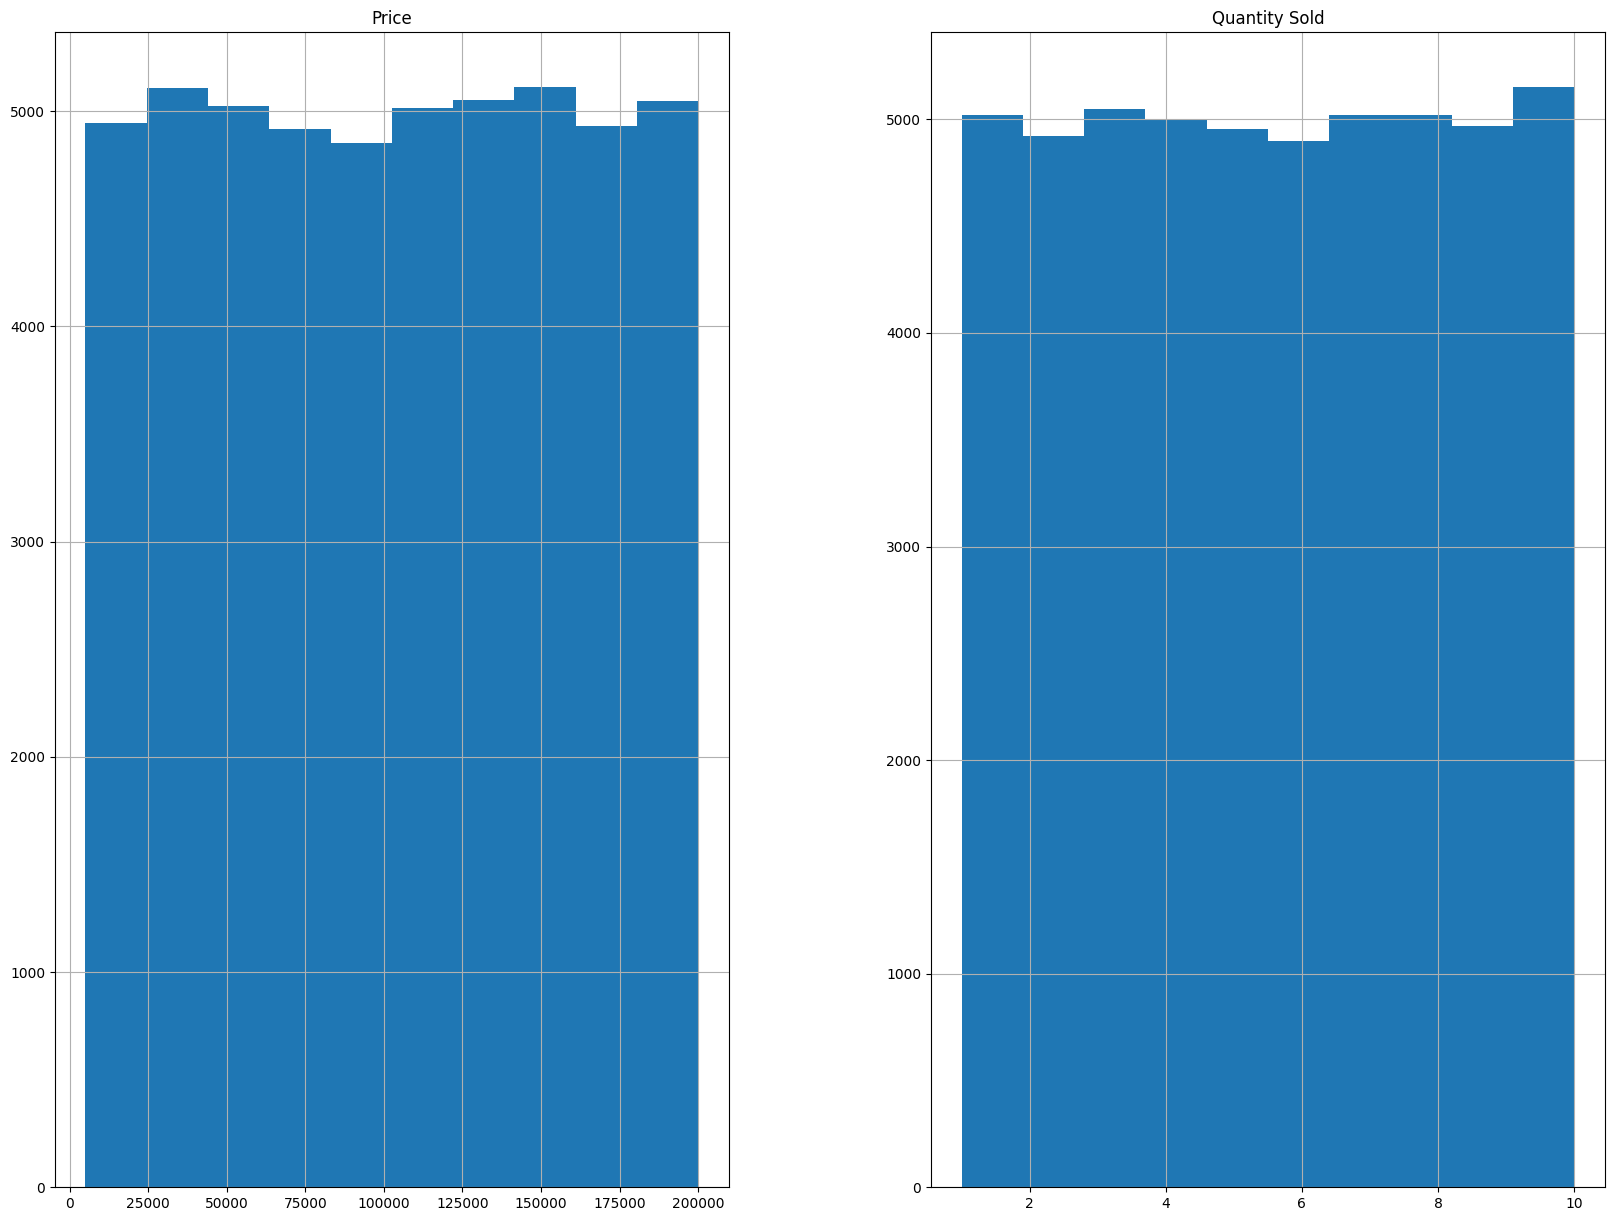

In [12]:
data.hist(figsize=(20, 15))
plt.show()

<Axes: >

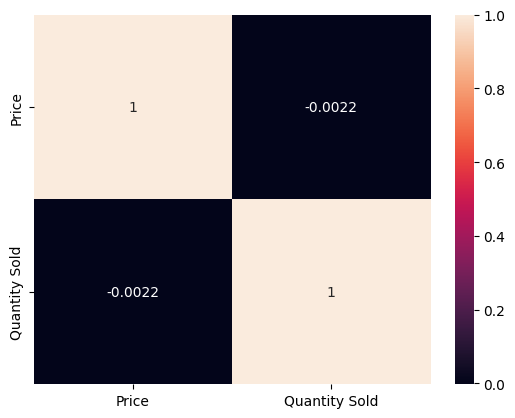

In [13]:
sns.heatmap(data.corr(numeric_only=True), annot=True)

In [14]:
c = data.corr(numeric_only=True).abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
print(pairs.sort_values(ascending=False).head(15))

Price  Quantity Sold    0.00222
dtype: float64


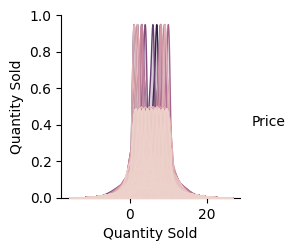

In [17]:
sns.pairplot(data[['Price', 'Quantity Sold']].dropna(), hue='Price')
plt.show()

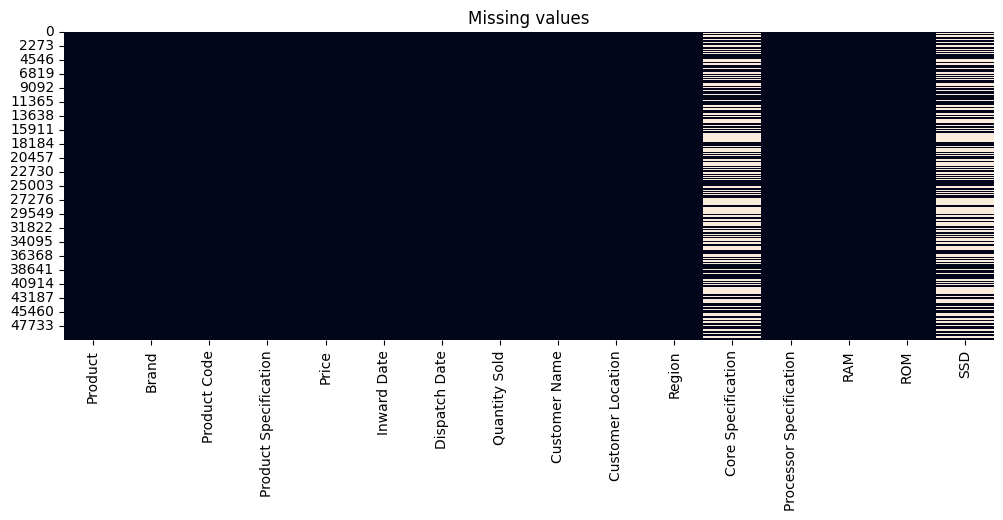

In [18]:
plt.figure(figsize=(12,4))
sns.heatmap(data.isna(), cbar=False)
plt.title("Missing values")
plt.show()

In [23]:
data['Inward Date'] = pd.to_datetime(data['Inward Date'])
data['Inward Month'] = data['Inward Date'].dt.to_period('M')

monthly_trend = data.groupby('Inward Month').agg(
    Total_Units_Sold=('Quantity Sold', 'sum'),
    Average_Price=('Price', 'mean')
).reset_index()

print("--- Monthly Sales Trend (First 5 Months) ---")
print(monthly_trend.head())

ram_price = data.groupby('RAM')['Price'].mean().reset_index().sort_values(by='Price', ascending=False)
print("\n--- Average Price by RAM ---")
print(ram_price)

top_processors = data['Processor Specification'].value_counts().head(5)
print("\n--- Top 5 Processor Specifications ---")
print(top_processors)

--- Monthly Sales Trend (First 5 Months) ---
  Inward Month  Total_Units_Sold  Average_Price
0      2023-03              4078   98906.651226
1      2023-04             11580  103883.338702
2      2023-05             11402  100170.158270
3      2023-06             10938  103462.396873
4      2023-07             11884  105204.734522

--- Average Price by RAM ---
    RAM          Price
3   4GB  103172.745634
4   6GB  103126.202433
2  32GB  102907.601335
1  16GB  102272.724997
0  12GB  102245.003617
5   8GB  102112.951852

--- Top 5 Processor Specifications ---
Processor Specification
MediaTek Dimensity    3640
Snapdragon 8 Gen      3614
Snapdragon 7s         3590
Samsung Exynos        3581
Apple A-Series        3565
Name: count, dtype: int64


/tmp/ipykernel_695/2488929874.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Total_Revenue', y='Brand', data=top_brands, palette='viridis')


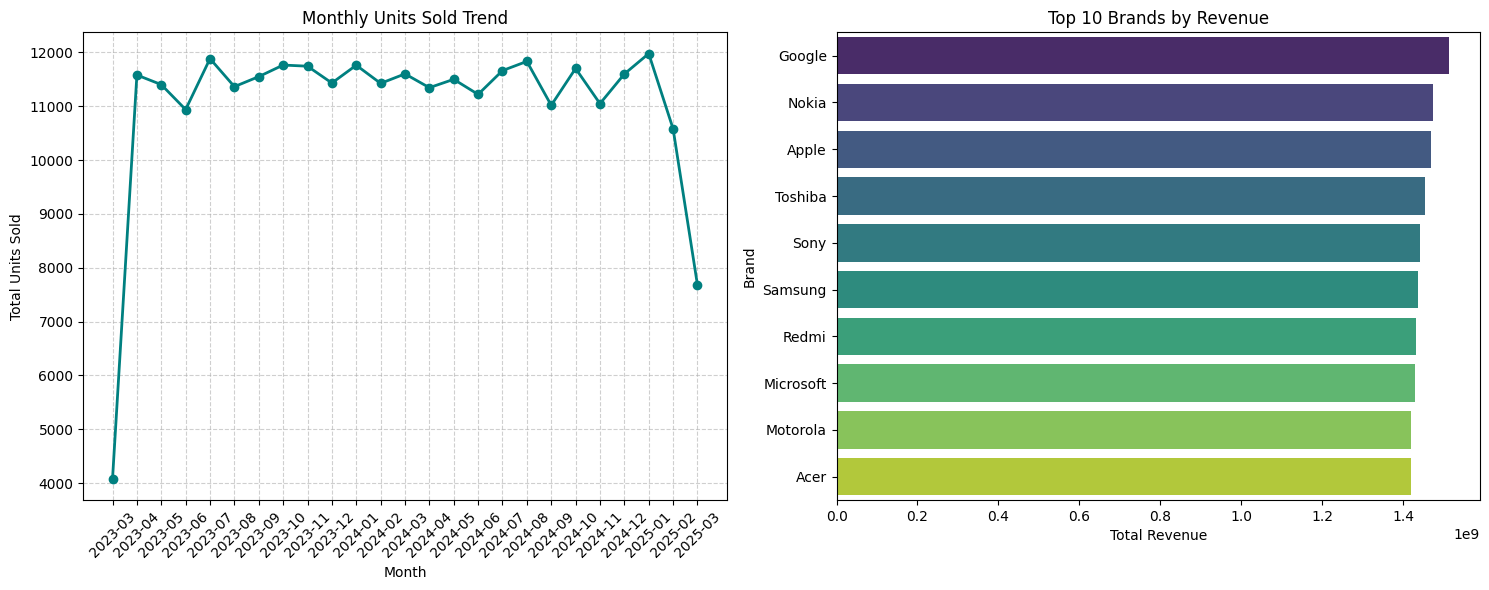

In [25]:
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
monthly_trend_sorted = monthly_trend.sort_values('Inward Month')
plt.plot(monthly_trend_sorted['Inward Month'].astype(str), monthly_trend_sorted['Total_Units_Sold'], marker='o', color='teal', linewidth=2)
plt.title('Monthly Units Sold Trend')
plt.xlabel('Month')
plt.ylabel('Total Units Sold')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
top_brands = brand_analysis.sort_values(by='Total_Revenue', ascending=False).head(10)
sns.barplot(x='Total_Revenue', y='Brand', data=top_brands, palette='viridis')
plt.title('Top 10 Brands by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Brand')

plt.tight_layout()
plt.show()